# Credit risk in Germany: from banking-system indicators to a borrower-level PD model

Ettore Mancuso

This notebook produces every number, table and figure in the paper (`paper/german_credit_risk.pdf`).
It has two parts:

1. **System level.** Corporate insolvencies and asset-quality indicators for German banks (Destatis, EBA, ECB, BaFin), with a source for every value.
2. **Borrower level.** Probability of Default (PD) models on the German Credit data (logistic regression scorecard, random forest, gradient boosting), a rating master scale, and the IRB capital those PDs would imply under the CRR.

Run it from the repository root or from `notebooks/`; paths are resolved automatically.

In [1]:
import sqlite3, sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_curve, brier_score_loss
from scipy.stats import binomtest

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from woe import WoEEncoder, woe_table
from irb import risk_weight, recalibrate, discrimination, PD_FLOOR_RETAIL

FIG, OUT = ROOT / "figures", ROOT / "outputs"
FIG.mkdir(exist_ok=True); OUT.mkdir(exist_ok=True)
SEED = 42
warnings.filterwarnings("ignore", category=FutureWarning)

BLUE, ORANGE, GREY, LIGHT, INK = "#2a78d6", "#eb6834", "#8c8b86", "#d9d8d3", "#2b2b2b"
plt.rcParams.update({
    "font.family": "serif", "font.serif": ["Liberation Serif", "Times New Roman", "DejaVu Serif"],
    "font.size": 9.5, "axes.titlesize": 10.5, "axes.titleweight": "bold",
    "axes.edgecolor": GREY, "axes.linewidth": 0.6, "axes.grid": True,
    "grid.color": "#ebeae6", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False, "figure.dpi": 110, "savefig.bbox": "tight",
    "pdf.fonttype": 42, "ps.fonttype": 42,  # embed real TrueType fonts: sharp in every PDF viewer
})

def save(fig, name):
    fig.savefig(FIG / f"{name}.pdf"); fig.savefig(FIG / f"{name}.png", dpi=200)

## 1. System level: insolvencies and bank asset quality

Hand-collected series in `data/macro/`. Each row carries its source.

In [2]:
ins = pd.read_csv(ROOT / "data/macro/insolvencies_de.csv")
npl = pd.read_csv(ROOT / "data/macro/npl_indicators.csv", parse_dates=["date"])
reg = pd.read_csv(ROOT / "data/macro/regulation_parameters.csv")

ins["yoy_pct"] = ins.corporate_insolvencies.pct_change() * 100
low = ins.loc[ins.corporate_insolvencies.idxmin()]
print(f"Trough: {int(low.year)} with {int(low.corporate_insolvencies):,} cases")
print(f"2025 vs trough: {ins.corporate_insolvencies.iloc[-1] / low.corporate_insolvencies - 1:+.1%}")
print(f"2025 vs 2019 (pre-Covid): {ins.set_index('year').loc[2025, 'corporate_insolvencies'] / ins.set_index('year').loc[2019, 'corporate_insolvencies'] - 1:+.1%}")
stock = npl[npl.indicator == "NPL stock"].set_index(npl[npl.indicator == "NPL stock"].date.dt.year)["value"]
print(f"German NPL stock 2021->2025: {stock[2021]} -> {stock[2025]} EUR bn ({stock[2025]/stock[2021]-1:+.1%})")
ins.tail(6)

Trough: 2021 with 13,993 cases
2025 vs trough: +72.0%
2025 vs 2019 (pre-Covid): +28.3%
German NPL stock 2021->2025: 29.7 -> 48.6 EUR bn (+63.6%)


,year,corporate_insolvencies,source,yoy_pct
10,2020,15841,"Destatis, Fachserie 2 Reihe 4.1, May 2023 (dev...",-15.510161
11,2021,13993,"Destatis, Fachserie 2 Reihe 4.1, May 2023 (dev...",-11.665930
12,2022,14590,"Destatis, Fachserie 2 Reihe 4.1, May 2023 (dev...",4.266419
13,2023,17814,Destatis press release; +22.1% vs 2022 (Destat...,22.097327
14,2024,21812,Destatis press release (via Unternehmeredition...,22.443022
15,2025,24064,"Destatis press release No. 085, 13 March 2026;...",10.324592


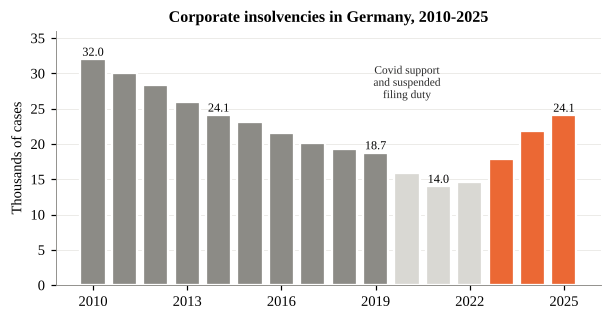

In [3]:
fig, ax = plt.subplots(figsize=(6.4, 3.0))
colors = [ORANGE if y >= 2023 else (LIGHT if y in (2020, 2021, 2022) else GREY) for y in ins.year]
ax.bar(ins.year, ins.corporate_insolvencies / 1000, color=colors, edgecolor="white", lw=1.5)
for y, v in zip(ins.year, ins.corporate_insolvencies):
    if y in (2010, 2014, 2019, 2021, 2025):
        ax.text(y, v / 1000 + 0.5, f"{v/1000:.1f}", ha="center", fontsize=8)
ax.set_ylabel("Thousands of cases"); ax.set_ylim(0, 36)
ax.set_xticks(ins.year[::3])
ax.set_title("Corporate insolvencies in Germany, 2010-2025")
ax.text(2020.0, 26.5, "Covid support\nand suspended\nfiling duty", fontsize=7.5, ha="center", color=INK)
ax.grid(axis="x", visible=False)
save(fig, "fig1_insolvencies")

,label,Germany,EU
0,"NPL ratio, all loans (Q4 2025)",1.61,1.82
1,"NPL ratio, commercial real estate (2019)",1.70,8.60
2,"NPL ratio, commercial real estate (Q4 2025)",6.90,4.10
3,Stage 2 share of loans (Q2 2026),15.30,8.90


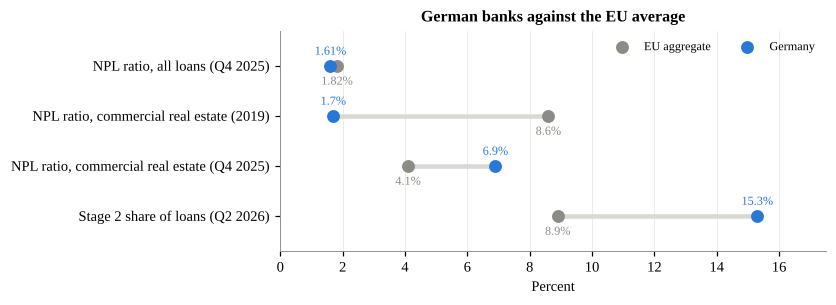

In [4]:
rows = [
    ("NPL ratio, all loans (Q4 2025)", "NPL ratio (all loans)", "2025-12-31"),
    ("NPL ratio, commercial real estate (2019)", "NPL ratio commercial real estate", "2019-12-31"),
    ("NPL ratio, commercial real estate (Q4 2025)", "NPL ratio commercial real estate", "2025-12-31"),
    ("Stage 2 share of loans (Q2 2026)", "Stage 2 share of loans at amortised cost", "2026-06-30"),
]
comp = []
for label, ind, d in rows:
    sel = npl[(npl.indicator == ind) & (npl.date == d)].set_index("geography")["value"]
    comp.append({"label": label, "Germany": sel["Germany"], "EU": sel["EU"]})
comp = pd.DataFrame(comp)
display(comp)

fig, ax = plt.subplots(figsize=(6.4, 2.6))
y = np.arange(len(comp))[::-1]
for yi, (_, r) in zip(y, comp.iterrows()):
    ax.plot([r.EU, r.Germany], [yi, yi], color=LIGHT, lw=3, zorder=1)
ax.scatter(comp.EU, y, s=55, color=GREY, label="EU aggregate", zorder=2)
ax.scatter(comp.Germany, y, s=55, color=BLUE, label="Germany", zorder=3)
for yi, (_, r) in zip(y, comp.iterrows()):
    ax.text(r.Germany, yi + 0.22, f"{r.Germany:g}%", ha="center", fontsize=8, color=BLUE)
    ax.text(r.EU, yi - 0.38, f"{r.EU:g}%", ha="center", fontsize=8, color=GREY)
ax.set_yticks(y, comp.label); ax.set_xlim(0, 17.5); ax.set_ylim(-0.7, len(comp) - 0.3)
ax.set_xlabel("Percent")
ax.set_title("German banks against the EU average")
ax.legend(loc="upper right", ncol=2, fontsize=8)
ax.grid(axis="y", visible=False)
save(fig, "fig2_npl_compare")

## 2. Borrower level: the German Credit data

1,000 consumer loans from a southern German bank (Hofmann, 1994; UCI Machine Learning Repository), 20 attributes plus a good/bad label.
Two caveats shape what follows:

* **Coding errors.** Grömping (2019) showed that several category labels in the widely circulated version are wrong (the corrected file is the *South German Credit* data). I therefore read the variables as anonymous categories and avoid interpreting their labels causally.
* **Over-sampling of defaults.** 30% of the loans are bad, far above any real retail book. The models rank borrowers on this sample; PDs are then recalibrated to a realistic central tendency before computing capital (Section 2.5).

I drop `personal_status_and_sex` and `foreign_worker`. Sex and nationality should not drive a credit decision, and under the EU AI Act creditworthiness scoring of natural persons is a high-risk use.

In [5]:
raw = pd.read_csv(ROOT / "data/raw/germancredit.csv")
raw["bad"] = (raw.creditability == "bad").astype(int)
EXCLUDED = ["personal_status_and_sex", "foreign_worker"]
FEATURES = [c for c in raw.columns if c not in EXCLUDED + ["creditability", "bad"]]
NUMERIC = [c for c in FEATURES if pd.api.types.is_numeric_dtype(raw[c])]
CATEG = [c for c in FEATURES if c not in NUMERIC]
print(raw.shape, "| default rate:", raw.bad.mean(), "| features used:", len(FEATURES))
print("numeric:", NUMERIC)

(1000, 22) | default rate: 0.3 | features used: 18
numeric: ['duration_in_month', 'credit_amount', 'installment_rate_in_percentage_of_disposable_income', 'present_residence_since', 'age_in_years', 'number_of_existing_credits_at_this_bank', 'number_of_people_being_liable_to_provide_maintenance_for']


### 2.1 Segment default rates with SQL

The queries live in `sql/segments.sql` and run on an in-memory SQLite copy of the data.

In [6]:
con = sqlite3.connect(":memory:")
raw.to_sql("loans", con, index=False)
queries = {}
for block in (ROOT / "sql/segments.sql").read_text().split("-- name: ")[1:]:
    name, sql = block.split("\n", 1)
    queries[name.strip()] = sql.strip()
seg = {name: pd.read_sql(q, con) for name, q in queries.items()}
for name, df in seg.items():
    print(name); display(df)

by_checking_account


,segment,n,defaults,default_rate_pct
0,... < 0 DM,274,135,49.3
1,0 <= ... < 200 DM,269,105,39.0
2,... >= 200 DM / salary assignments for at leas...,63,14,22.2
3,no checking account,394,46,11.7


by_duration_band


,segment,n,defaults,default_rate_pct,avg_amount_dm
0,01-12 months,359,76,21.2,1811.0
1,13-24 months,411,122,29.7,2924.0
2,25-36 months,143,57,39.9,5274.0
3,37+ months,87,45,51.7,7646.0


by_purpose


,segment,n,default_rate_pct,exposure_k_dm
0,education,50,44.0,159.0
1,car (new),234,38.0,717.0
2,repairs,22,36.4,60.0
3,business,97,35.1,403.0
4,furniture/equipment,181,32.0,555.0
5,radio/television,280,22.1,697.0
6,car (used),103,16.5,553.0


### 2.2 Weight of Evidence and Information Value

Stratified 70/30 split. WoE bins are fitted on the training set only.

In [7]:
X, y = raw[FEATURES], raw["bad"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, stratify=y, random_state=SEED)
enc = WoEEncoder(n_bins=5).fit(X_tr, y_tr)
iv = enc.information_values(X_tr, y_tr)
iv_tab = iv.rename("IV").to_frame()
iv_tab["strength"] = pd.cut(iv_tab.IV, [-1, 0.02, 0.1, 0.3, 99], labels=["useless", "weak", "medium", "strong"])
display(iv_tab.round(3))
SELECTED = iv[iv >= 0.02].index.tolist()
print(len(SELECTED), "variables with IV >= 0.02 kept for the scorecard")

,IV,strength
status_of_existing_checking_account,0.630,strong
credit_history,0.252,medium
savings_account_and_bonds,0.221,medium
duration_in_month,0.184,medium
property,0.139,medium
present_employment_since,0.139,medium
purpose,0.129,medium
other_installment_plans,0.118,medium
housing,0.103,medium
credit_amount,0.064,weak


14 variables with IV >= 0.02 kept for the scorecard


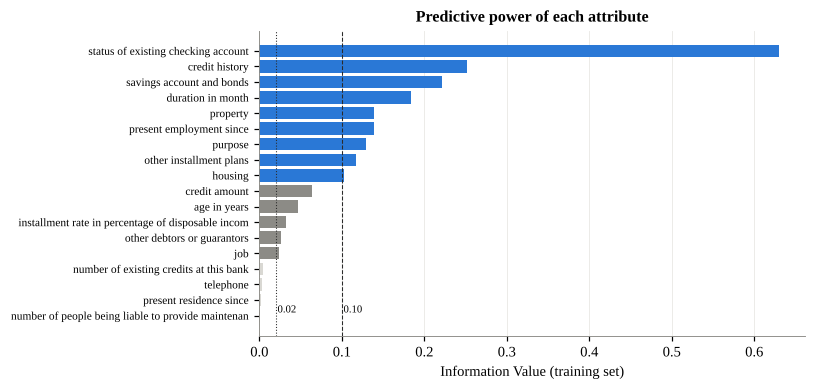

In [8]:
fig, ax = plt.subplots(figsize=(6.4, 3.6))
s = iv.sort_values()
ax.barh(range(len(s)), s.values, color=[BLUE if v >= 0.1 else (GREY if v >= 0.02 else LIGHT) for v in s.values])
ax.set_yticks(range(len(s)), [n.replace("_", " ")[:50] for n in s.index], fontsize=7.5)
ax.axvline(0.02, color=INK, lw=0.7, ls=":"); ax.axvline(0.1, color=INK, lw=0.7, ls="--")
ax.text(0.022, 0.2, "0.02", fontsize=7); ax.text(0.102, 0.2, "0.10", fontsize=7)
ax.set_xlabel("Information Value (training set)")
ax.set_title("Predictive power of each attribute")
ax.grid(axis="y", visible=False)
save(fig, "fig3_iv")

### 2.3 Three PD models

* **Scorecard:** logistic regression on WoE-transformed variables (IV ≥ 0.02).
* **Random forest** and **gradient boosting** on one-hot encoded data.

All three are compared with 5-fold cross-validated AUC on the training set and then on the untouched test set.

In [9]:
onehot = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), CATEG)], remainder="passthrough")
models = {
    "Logistic scorecard (WoE)": None,  # handled separately because of the WoE step
    "Random forest": Pipeline([("prep", onehot), ("m", RandomForestClassifier(
        n_estimators=500, min_samples_leaf=5, max_features="sqrt", random_state=SEED, n_jobs=-1))]),
    "Gradient boosting": Pipeline([("prep", onehot), ("m", GradientBoostingClassifier(
        n_estimators=300, learning_rate=0.05, max_depth=2, subsample=0.8, random_state=SEED))]),
}

class WoELogit:
    """WoE encoding + logistic regression, refitted inside each CV fold."""
    def __init__(self, features): self.features = features
    def fit(self, X, y):
        self.enc = WoEEncoder(5).fit(X[self.features], y)
        self.lr = LogisticRegression(C=1.0, max_iter=1000).fit(self.enc.transform(X[self.features]), y)
        return self
    def predict_proba(self, X): return self.lr.predict_proba(self.enc.transform(X[self.features]))
    def get_params(self, deep=False): return {"features": self.features}
    def set_params(self, **p): self.features = p.get("features", self.features); return self

models["Logistic scorecard (WoE)"] = WoELogit(SELECTED)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
results, test_scores = [], {}
for name, model in models.items():
    cv_auc = []
    for tr, va in skf.split(X_tr, y_tr):
        m = model.fit(X_tr.iloc[tr], y_tr.iloc[tr])
        cv_auc.append(discrimination(y_tr.iloc[va], m.predict_proba(X_tr.iloc[va])[:, 1])["AUC"])
    model.fit(X_tr, y_tr)
    p = model.predict_proba(X_te)[:, 1]
    test_scores[name] = p
    d = discrimination(y_te, p)
    results.append({"model": name, "CV AUC (mean)": np.mean(cv_auc), "CV AUC (sd)": np.std(cv_auc),
                    "Test AUC": d["AUC"], "Test Gini": d["Gini"], "Test KS": d["KS"],
                    "Test Brier": brier_score_loss(y_te, p)})
res = pd.DataFrame(results).set_index("model")
res.round(3)

,CV AUC (mean),CV AUC (sd),Test AUC,Test Gini,Test KS,Test Brier
model,,,,,,
Logistic scorecard (WoE),0.758,0.019,0.801,0.601,0.502,0.159
Random forest,0.783,0.035,0.794,0.587,0.481,0.166
Gradient boosting,0.764,0.019,0.796,0.592,0.462,0.159


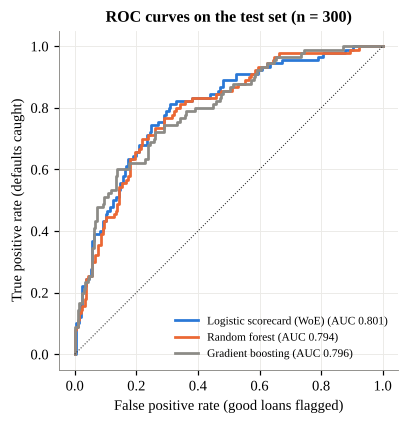

In [10]:
fig, ax = plt.subplots(figsize=(4.6, 4.0))
for (name, p), c in zip(test_scores.items(), [BLUE, ORANGE, GREY]):
    fpr, tpr, _ = roc_curve(y_te, p)
    ax.plot(fpr, tpr, color=c, lw=1.8, label=f"{name} (AUC {res.loc[name, 'Test AUC']:.3f})")
ax.plot([0, 1], [0, 1], color=INK, lw=0.7, ls=":")
ax.set_xlabel("False positive rate (good loans flagged)"); ax.set_ylabel("True positive rate (defaults caught)")
ax.set_title("ROC curves on the test set (n = 300)")
ax.legend(loc="lower right", fontsize=7.5); ax.set_aspect("equal")
save(fig, "fig4_roc")

### 2.4 Inside the scorecard

Coefficients from an unpenalised logit (statsmodels) on the same WoE variables. With WoE defined as ln(%good/%bad), every coefficient should be negative: a safer bin lowers the log-odds of default.

In [11]:
W_tr = enc.transform(X_tr[SELECTED])
logit = sm.Logit(y_tr, sm.add_constant(W_tr)).fit(disp=0)
coef = pd.DataFrame({"coef": logit.params, "se": logit.bse, "p_value": logit.pvalues}).round(3)
display(coef)
print("Pseudo R2 (McFadden):", round(logit.prsquared, 3))
print("Coefficients with the expected negative sign:", int((logit.params.drop("const") < 0).sum()), "of", len(SELECTED))

,coef,se,p_value
const,-0.860,0.100,0.000
status_of_existing_checking_account,-0.764,0.130,0.000
duration_in_month,-0.871,0.248,0.000
credit_history,-0.677,0.202,0.001
purpose,-0.935,0.280,0.001
credit_amount,-0.605,0.422,0.152
savings_account_and_bonds,-0.915,0.230,0.000
present_employment_since,-0.827,0.266,0.002
installment_rate_in_percentage_of_disposable_income,-1.734,0.557,0.002
other_debtors_or_guarantors,-0.842,0.598,0.159


Pseudo R2 (McFadden): 0.234
Coefficients with the expected negative sign: 13 of 14


### 2.5 Rating grades and calibration

To grade the whole portfolio without in-sample bias, each loan gets an out-of-fold PD from 5-fold `cross_val_predict` with the scorecard.
The sample PD (30% average) is then moved to a central tendency of **3%** by shifting the intercept of the log-odds until the mean PD equals 3%; the ranking does not change. The 3% is my assumption for a consumer-loan book, not a property of the data; Section 2.6 shows how capital changes at 2% and 5%.

In [12]:
oof = np.zeros(len(X))
for tr, va in skf.split(X, y):  # out-of-fold PD: each loan is scored by a model that never saw it
    oof[va] = WoELogit(SELECTED).fit(X.iloc[tr], y.iloc[tr]).predict_proba(X.iloc[va])[:, 1]
SAMPLE_RATE, CT = y.mean(), 0.03
port = raw[["credit_amount", "duration_in_month", "purpose", "bad"]].copy()
port["pd_sample"] = oof
port["pd"] = np.maximum(recalibrate(oof, CT), PD_FLOOR_RETAIL)

edges = [0, 0.005, 0.01, 0.02, 0.04, 0.08, 0.15, 1.0]
labels = ["A", "B", "C", "D", "E", "F", "G"]
port["grade"] = pd.cut(port.pd, edges, labels=labels, right=False)
g = port.groupby("grade", observed=False).agg(
    n=("bad", "size"), defaults=("bad", "sum"), observed_dr=("bad", "mean"),
    mean_pd_sample=("pd_sample", "mean"), mean_pd=("pd", "mean"),
    exposure_dm=("credit_amount", "sum"))
g["share_n"] = g.n / g.n.sum()
g["pd_band"] = [f"{a:.1%}-{b:.1%}" for a, b in zip(edges[:-1], edges[1:])]
# Binomial test per grade (on the sample scale): is the observed count consistent with the predicted PD?
g["binom_p"] = [binomtest(int(r.defaults), int(r.n), r.mean_pd_sample).pvalue if r.n > 0 else np.nan
                for _, r in g.iterrows()]
display(g.round(3))
mono = g.observed_dr.dropna().is_monotonic_increasing
print("Observed default rate increases monotonically across grades:", mono)
print("Out-of-fold scorecard AUC on all 1,000 loans:", round(discrimination(y, oof)["AUC"], 3))

,n,defaults,observed_dr,mean_pd_sample,mean_pd,exposure_dm,share_n,pd_band,binom_p
grade,,,,,,,,,
A,275,19,0.069,0.059,0.003,690833,0.275,0.0%-0.5%,0.443
B,160,26,0.162,0.144,0.007,508648,0.160,0.5%-1.0%,0.499
C,163,43,0.264,0.255,0.015,473434,0.163,1.0%-2.0%,0.788
D,175,79,0.451,0.398,0.028,604556,0.175,2.0%-4.0%,0.165
E,132,69,0.523,0.573,0.056,432060,0.132,4.0%-8.0%,0.254
F,64,42,0.656,0.732,0.108,327206,0.064,8.0%-15.0%,0.203
G,31,22,0.710,0.857,0.213,234521,0.031,15.0%-100.0%,0.034


Observed default rate increases monotonically across grades: True
Out-of-fold scorecard AUC on all 1,000 loans: 0.774


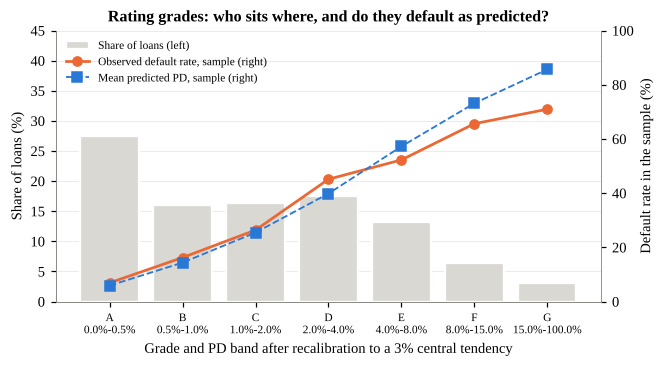

In [13]:
fig, ax1 = plt.subplots(figsize=(6.4, 3.2))
x = np.arange(len(g))
ax1.bar(x, g.share_n * 100, color=LIGHT, edgecolor="white", lw=1.5, label="Share of loans (left)")
ax1.set_ylabel("Share of loans (%)"); ax1.set_ylim(0, 45); ax1.set_xticks(x, [f"{l}\n{b}" for l, b in zip(g.index, g.pd_band)], fontsize=7.5)
ax2 = ax1.twinx()
ax2.plot(x, g.observed_dr * 100, color=ORANGE, marker="o", lw=1.8, label="Observed default rate, sample (right)")
ax2.plot(x, g.mean_pd_sample * 100, color=BLUE, marker="s", lw=1.2, ls="--", label="Mean predicted PD, sample (right)")
ax2.set_ylabel("Default rate in the sample (%)"); ax2.set_ylim(0, 100); ax2.spines["right"].set_visible(True); ax2.grid(False)
ax1.set_title("Rating grades: who sits where, and do they default as predicted?")
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper left", fontsize=7.5)
ax1.grid(axis="x", visible=False)
ax1.set_xlabel("Grade and PD band after recalibration to a 3% central tendency")
save(fig, "fig5_grades")

### 2.6 From PD to capital

Each loan is treated as an *other retail* exposure under the IRB approach (CRR Art. 154). EAD is the credit amount, LGD is 45% in the baseline (an assumption: the data contain no recoveries; the CRR3 floor for unsecured retail is lower, so 45% is conservative). The result is compared with the 75% standardised risk weight for regulatory retail (CRR Art. 123) and with the output floor.

In [14]:
LGD = 0.45
port["rw_irb"] = risk_weight(port.pd, LGD)
port["rwa_irb"] = port.rw_irb * port.credit_amount
port["rwa_sa"] = 0.75 * port.credit_amount
port["el"] = port.pd * LGD * port.credit_amount
ead = port.credit_amount.sum()
summary = {
    "EAD (DM m)": ead / 1e6,
    "Average IRB risk weight": port.rwa_irb.sum() / ead,
    "Standardised risk weight": 0.75,
    "IRB RWA / SA RWA": port.rwa_irb.sum() / port.rwa_sa.sum(),
    "Expected loss (% of EAD)": port.el.sum() / ead,
    "Capital at 8% of IRB RWA (% of EAD)": 0.08 * port.rwa_irb.sum() / ead,
}
display(pd.Series(summary).round(4))
for fl in (0.50, 0.725):
    floor = fl * port.rwa_sa.sum()
    print(f"Output floor {fl:.1%}: floor RWA = {floor/1e6:.2f}m vs IRB RWA {port.rwa_irb.sum()/1e6:.2f}m -> binding: {floor > port.rwa_irb.sum()}")

by_grade = port.groupby("grade", observed=False).apply(lambda d: pd.Series({
    "mean_pd": d.pd.mean(), "rw_irb": d.rwa_irb.sum() / d.credit_amount.sum() if len(d) else np.nan,
    "el_pct": d.el.sum() / d.credit_amount.sum() if len(d) else np.nan,
    "exposure_share": d.credit_amount.sum() / ead}))
display(by_grade.round(4))

EAD (DM m)                             3.2713
Average IRB risk weight                0.5356
Standardised risk weight               0.7500
IRB RWA / SA RWA                       0.7141
Expected loss (% of EAD)               0.0191
Capital at 8% of IRB RWA (% of EAD)    0.0428
dtype: float64

Output floor 50.0%: floor RWA = 1.23m vs IRB RWA 1.75m -> binding: False
Output floor 72.5%: floor RWA = 1.78m vs IRB RWA 1.75m -> binding: True


,mean_pd,rw_irb,el_pct,exposure_share
grade,,,,
A,0.0027,0.2184,0.0012,0.2112
B,0.0072,0.3901,0.0032,0.1555
C,0.0146,0.5220,0.0065,0.1447
D,0.0280,0.6179,0.0126,0.1848
E,0.0555,0.6714,0.0248,0.1321
F,0.1076,0.7696,0.0472,0.1000
G,0.2126,1.0244,0.0986,0.0717


In [15]:
sens = []
for ct in (0.02, 0.03, 0.05):
    p_ = np.maximum(recalibrate(oof, ct), PD_FLOOR_RETAIL)
    for lgd in (0.30, 0.45):
        rw_ = risk_weight(p_, lgd)
        sens.append({"central tendency": ct, "LGD": lgd,
                     "avg IRB RW": (rw_ * port.credit_amount).sum() / ead,
                     "IRB/SA": (rw_ * port.credit_amount).sum() / (0.75 * ead),
                     "EL % EAD": (p_ * lgd * port.credit_amount).sum() / ead})
sens = pd.DataFrame(sens)
sens["floor 72.5% binding"] = sens["IRB/SA"] < 0.725
sens.round(3)

,central tendency,LGD,avg IRB RW,IRB/SA,EL % EAD,floor 72.5% binding
0,0.02,0.30,0.312,0.416,0.009,True
1,0.02,0.45,0.468,0.624,0.013,True
2,0.03,0.30,0.357,0.476,0.013,True
3,0.03,0.45,0.536,0.714,0.019,True
4,0.05,0.30,0.419,0.558,0.021,True
5,0.05,0.45,0.628,0.837,0.031,False


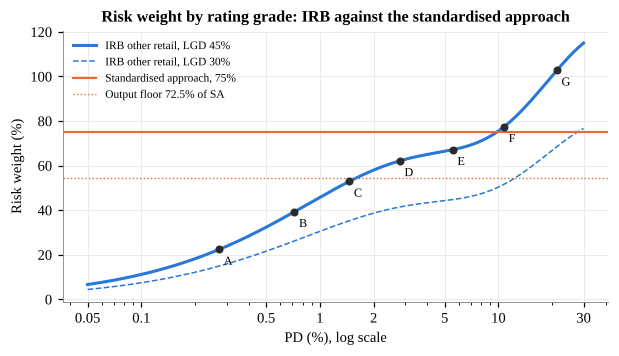

In [16]:
fig, ax = plt.subplots(figsize=(6.4, 3.2))
grid = np.logspace(np.log10(0.0005), np.log10(0.30), 300)
ax.plot(grid * 100, risk_weight(grid, 0.45) * 100, color=BLUE, lw=2, label="IRB other retail, LGD 45%")
ax.plot(grid * 100, risk_weight(grid, 0.30) * 100, color=BLUE, lw=1, ls="--", label="IRB other retail, LGD 30%")
ax.axhline(75, color=ORANGE, lw=1.4, label="Standardised approach, 75%")
ax.axhline(0.725 * 75, color=ORANGE, lw=0.9, ls=":", label="Output floor 72.5% of SA")
for lbl, r in by_grade.dropna().iterrows():
    ax.scatter(r.mean_pd * 100, risk_weight(r.mean_pd, 0.45) * 100, color=INK, s=18, zorder=3)
    ax.annotate(lbl, (r.mean_pd * 100, risk_weight(r.mean_pd, 0.45) * 100), xytext=(3, -10),
                textcoords="offset points", fontsize=8)
ax.set_xscale("log"); ax.set_xlabel("PD (%), log scale"); ax.set_ylabel("Risk weight (%)")
ax.set_xticks([0.05, 0.1, 0.5, 1, 2, 5, 10, 30], ["0.05", "0.1", "0.5", "1", "2", "5", "10", "30"])
ax.set_title("Risk weight by rating grade: IRB against the standardised approach")
ax.legend(loc="upper left", fontsize=7.5)
save(fig, "fig6_risk_weights")

## 3. Exports for reporting

CSV files in `outputs/` feed the Power BI report (one row per loan, one row per grade, model comparison).

In [17]:
port.to_csv(OUT / "scored_portfolio.csv", index_label="loan_id")
g.join(by_grade[["rw_irb", "el_pct", "exposure_share"]]).to_csv(OUT / "grade_summary.csv")
res.to_csv(OUT / "model_comparison.csv")
iv_tab.to_csv(OUT / "information_values.csv")
sens.to_csv(OUT / "capital_sensitivity.csv", index=False)
pd.Series(X_te.index, name="row").to_csv(OUT / "test_index.csv", index=False)  # same split for the R script
print(sorted(p.name for p in OUT.glob("*.csv")))

['capital_sensitivity.csv', 'grade_summary.csv', 'information_values.csv', 'model_comparison.csv', 'r_glm_result.csv', 'scored_portfolio.csv', 'test_index.csv']
